[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ErvinasE/commit-message-generator/blob/main/1.5/cnn_Transfer_learning_FashionMNIST.ipynb)

# Perkeliamasis mokymasis (*transfer learning*): parduotuvės prekių nuotraukos

Šis sąsiuvinis yra perdarytas dėstytojo A. Laukaičio sąsiuvinis `cnn_Transfer_learning.ipynb`.

**Idėja:** užuot mokę tinklą nuo nulio (kaip 1.4 sąsiuvinyje), paimame tinklą **EfficientNetV2-B1**, kurį „Google“
jau išmokė su milijonu ImageNet nuotraukų. Jo konvoliuciniai sluoksniai jau moka atpažinti kraštus, tekstūras ir formas.
Nuimame jo paskutinį sluoksnį (1 000 ImageNet klasių) ir uždedame savo sluoksnį su 10 klasių.

* **1 skyrius**: tinklo svoriai užšaldyti (*frozen*), mokome tik naują paskutinį sluoksnį;
* **2 skyrius**: „atšildome“ visą tinklą ir mažu mokymosi greičiu jį deriname (*fine-tuning*) su papildytais
  (*augmented*) duomenimis.

| | Originalas | Šis sąsiuvinis |
|---|---|---|
| Duomenys | CIFAR-10 (50 000 + 10 000) | Fashion-MNIST, tie patys 6 000 + 1 000 kaip 1.4 sąsiuvinyje |
| Iš anksto išmokytas tinklas | EfficientNetV2-B1 iš TF Hub (ImageNet-21k) | EfficientNetV2-B1 iš `keras.applications` (ImageNet-1k) |
| Įėjimo dydis | 32×32 → 240×240 | 28×28 → 240×240 |

**Kodėl `keras.applications`, o ne TF Hub?** TF Hub sluoksnis `hub.KerasLayer` neveikia su Keras 3 (dabartine Colab versija),
todėl originale teko diegti seną `tf_keras` paketą. `keras.applications` turi tą pačią EfficientNetV2-B1 architektūrą
ir veikia su Keras 3 be jokių apėjimų. Skirtumas tik tas, kad jo svoriai išmokyti su ImageNet-1k (1 000 klasių),
o ne su didesniu ImageNet-21k.

Kadangi naudojami tie patys duomenys kaip 1.4 sąsiuvinyje, rezultatus galima tiesiogiai palyginti su tinklu,
išmokytu nuo nulio (85,2 %).

**Būtinai įjunkite GPU** (*Runtime → Change runtime type → T4 GPU*). Su GPU sąsiuvinis turėtų užtrukti kelias minutes;
be GPU jis vykdomas ilgai (kompiuteryje su 4 procesoriaus branduoliais visas sąsiuvinis truko 28 min.).

In [1]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
import keras
from keras import layers
import matplotlib.pyplot as plt

keras.utils.set_random_seed(42)

---
# 1 skyrius. Sukuriame modelį, jį išmokome ir išsaugome

### 1 žingsnis. Įkeliame ir paruošiame Fashion-MNIST duomenis

Duomenys tie patys kaip 1.4 sąsiuvinyje (CSV: `label` + 784 taškai). Skiriasi paruošimas:

* EfficientNet išmokytas su **spalvotomis** nuotraukomis (3 kanalai), todėl vienintelį pilką kanalą nukopijuojame
  3 kartus (`np.repeat`): R = G = B;
* taškų **nedalijame iš 255**: `keras.applications` EfficientNetV2 viduje turi savo normalizavimo sluoksnį
  ir tikisi reikšmių 0–255 (originalo TF Hub modelis tikėjosi 0–1).

In [2]:
GITHUB_BRANCH = 'main'
DATA_URL = f'https://raw.githubusercontent.com/ErvinasE/commit-message-generator/{GITHUB_BRANCH}/1.5/data/'
data_dir = 'data/' if os.path.exists('data/fashion-mnist_train.csv.gz') else DATA_URL

train_df = pd.read_csv(data_dir + 'fashion-mnist_train.csv.gz')
test_df = pd.read_csv(data_dir + 'fashion-mnist_test.csv.gz')


def to_images(df):
    labels = df['label'].to_numpy().reshape(-1, 1)
    images = df.drop(columns='label').to_numpy().reshape(-1, 28, 28, 1).astype('float32')
    images = np.repeat(images, 3, axis=-1)     # 1 pilkas kanalas -> 3 vienodi kanalai
    return images, labels


train_images, train_labels = to_images(train_df)
test_images, test_labels = to_images(test_df)

class_names = ['Marškinėliai', 'Kelnės', 'Megztinis', 'Suknelė', 'Paltas',
               'Sandalas', 'Marškiniai', 'Sportbatis', 'Rankinė', 'Aulinukas']

print('train_images:', train_images.shape, ' reikšmės nuo', train_images.min(), 'iki', train_images.max())
print('test_images: ', test_images.shape)

train_images: (6000, 28, 28, 3)  reikšmės nuo 0.0 iki 255.0
test_images:  (1000, 28, 28, 3)


### 2 žingsnis. Iš anksto išmokytas požymių išskyrėjas (*feature extractor*)

* `include_top=False`: be paskutinio klasifikavimo sluoksnio (1 000 ImageNet klasių);
* `pooling='avg'`: paskutinį požymių žemėlapį suvidurkina į **1 280 skaičių vektorių**, kuris „aprašo“ nuotrauką;
* `weights='imagenet'`: parsisiunčia ImageNet išmokytus svorius;
* `feature_extractor.trainable = False`: šių svorių mokymo metu **nekeisime**.

In [3]:
IMAGE_SHAPE = (240, 240)

feature_extractor = keras.applications.EfficientNetV2B1(include_top=False, weights='imagenet', pooling='avg',
                                                        input_shape=(IMAGE_SHAPE[0], IMAGE_SHAPE[1], 3))
feature_extractor.trainable = False

### 3 žingsnis. Modelis

Trys sluoksniai, kaip originale:
1. `Resizing(240, 240)`: padidina 28×28 nuotrauką iki 240×240, nes EfficientNetV2-B1 išmokytas su tokio dydžio nuotraukomis;
2. `feature_extractor`: EfficientNetV2-B1 (užšaldytas), išėjimas 1 280 skaičių;
3. `Dense(10)`: mūsų naujas klasifikatorius, 1 280 × 10 + 10 = **12 810** parametrų. Tik jie bus mokomi.

In [4]:
num_classes = len(class_names)

model = keras.Sequential([
    keras.Input(shape=(28, 28, 3)),
    layers.Resizing(IMAGE_SHAPE[0], IMAGE_SHAPE[1]),
    feature_extractor,
    layers.Dense(num_classes),
])

model.compile(optimizer='adam', loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 240, 240, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-b1 (Functional)  │ (None, 1280)           │     6,931,124 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        12,810 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,943,934 (26.49 MB)

 Trainable params: 12,810 (50.04 KB)

 Non-trainable params: 6,931,124 (26.44 MB)

## model.fit

5 epochos (originale 20, bet ten buvo GPU ir CIFAR). Kaip 1.4 sąsiuvinyje, 10 % mokymo nuotraukų atidedame validavimui.

In [5]:
history = model.fit(train_images, train_labels, epochs=5, validation_split=0.1)

Epoch 1/5


  1/169 ━━━━━━━━━━━━━━━━━━━━ 40:18 14s/step - accuracy: 0.0625 - loss: 2.4970

  2/169 ━━━━━━━━━━━━━━━━━━━━ 1:37 584ms/step - accuracy: 0.0625 - loss: 2.4252

  3/169 ━━━━━━━━━━━━━━━━━━━━ 1:38 593ms/step - accuracy: 0.1146 - loss: 2.3569

  4/169 ━━━━━━━━━━━━━━━━━━━━ 1:37 590ms/step - accuracy: 0.1250 - loss: 2.3128

...

166/169 ━━━━━━━━━━━━━━━━━━━━ 2s 703ms/step - accuracy: 0.8829 - loss: 0.3379

167/169 ━━━━━━━━━━━━━━━━━━━━ 1s 702ms/step - accuracy: 0.8830 - loss: 0.3378

168/169 ━━━━━━━━━━━━━━━━━━━━ 0s 701ms/step - accuracy: 0.8830 - loss: 0.3378

169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 700ms/step - accuracy: 0.8826 - loss: 0.3381

169/169 ━━━━━━━━━━━━━━━━━━━━ 130s 767ms/step - accuracy: 0.8826 - loss: 0.3381 - val_accuracy: 0.8700 - val_loss: 0.3733


In [6]:
test_loss, test_acc = model.evaluate(test_images, test_labels)
frozen_test_acc = test_acc
print(test_acc)

 1/32 ━━━━━━━━━━━━━━━━━━━━ 20s 676ms/step - accuracy: 0.8750 - loss: 0.3098

 2/32 ━━━━━━━━━━━━━━━━━━━━ 19s 656ms/step - accuracy: 0.8906 - loss: 0.3209

 3/32 ━━━━━━━━━━━━━━━━━━━━ 18s 639ms/step - accuracy: 0.8646 - loss: 0.3705

 4/32 ━━━━━━━━━━━━━━━━━━━━ 17s 625ms/step - accuracy: 0.8828 - loss: 0.3420

 5/32 ━━━━━━━━━━━━━━━━━━━━ 16s 620ms/step - accuracy: 0.8875 - loss: 0.3474

...

30/32 ━━━━━━━━━━━━━━━━━━━━ 1s 604ms/step - accuracy: 0.8771 - loss: 0.3416

31/32 ━━━━━━━━━━━━━━━━━━━━ 0s 604ms/step - accuracy: 0.8760 - loss: 0.3398

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 592ms/step - accuracy: 0.8770 - loss: 0.3379

32/32 ━━━━━━━━━━━━━━━━━━━━ 19s 593ms/step - accuracy: 0.8770 - loss: 0.3379


0.8769999742507935


**Rezultatas:** su užšaldytu EfficientNet ir tik 12 810 mokomų parametrų testavimo tikslumas yra **87,7 %**,
t. y. daugiau nei 1.4 sąsiuvinio tinklo, mokyto nuo nulio (85,2 %). Validavimo nuostolis per visas 5 epochas mažėjo
(0,51 → 0,37), todėl persimokymo nėra; dar kelios epochos tikriausiai šiek tiek padėtų.
Tinklas niekada nematė mažų nespalvotų drabužių nuotraukų, tačiau iš ImageNet išmokti požymiai (kraštai, tekstūros, formos)
tinka ir čia.

Išsaugome modelį. Originale jis buvo išsaugomas `SavedModel` aplanku ir suspaudžiamas į ZIP;
Keras 3 visą modelį (architektūrą, svorius ir optimizatoriaus būseną) išsaugo į vieną `.keras` failą.

In [7]:
export_path = 'fashion_efficientnetv2b1.keras'
model.save(export_path)
print('Failo dydis: {:.1f} MB'.format(os.path.getsize(export_path) / 1e6))

Failo dydis: 29.1 MB


---
### Pirmosios 100 testavimo nuotraukų ir modelio atsakymai

Po nuotrauka: `tikroji klasė/prognozė`. Žalia = teisingai, raudona = klaida.
Originale prognozė buvo daroma kiekvienai nuotraukai atskirai (100 `predict` kvietimų); čia visos 100 vienu kartu.

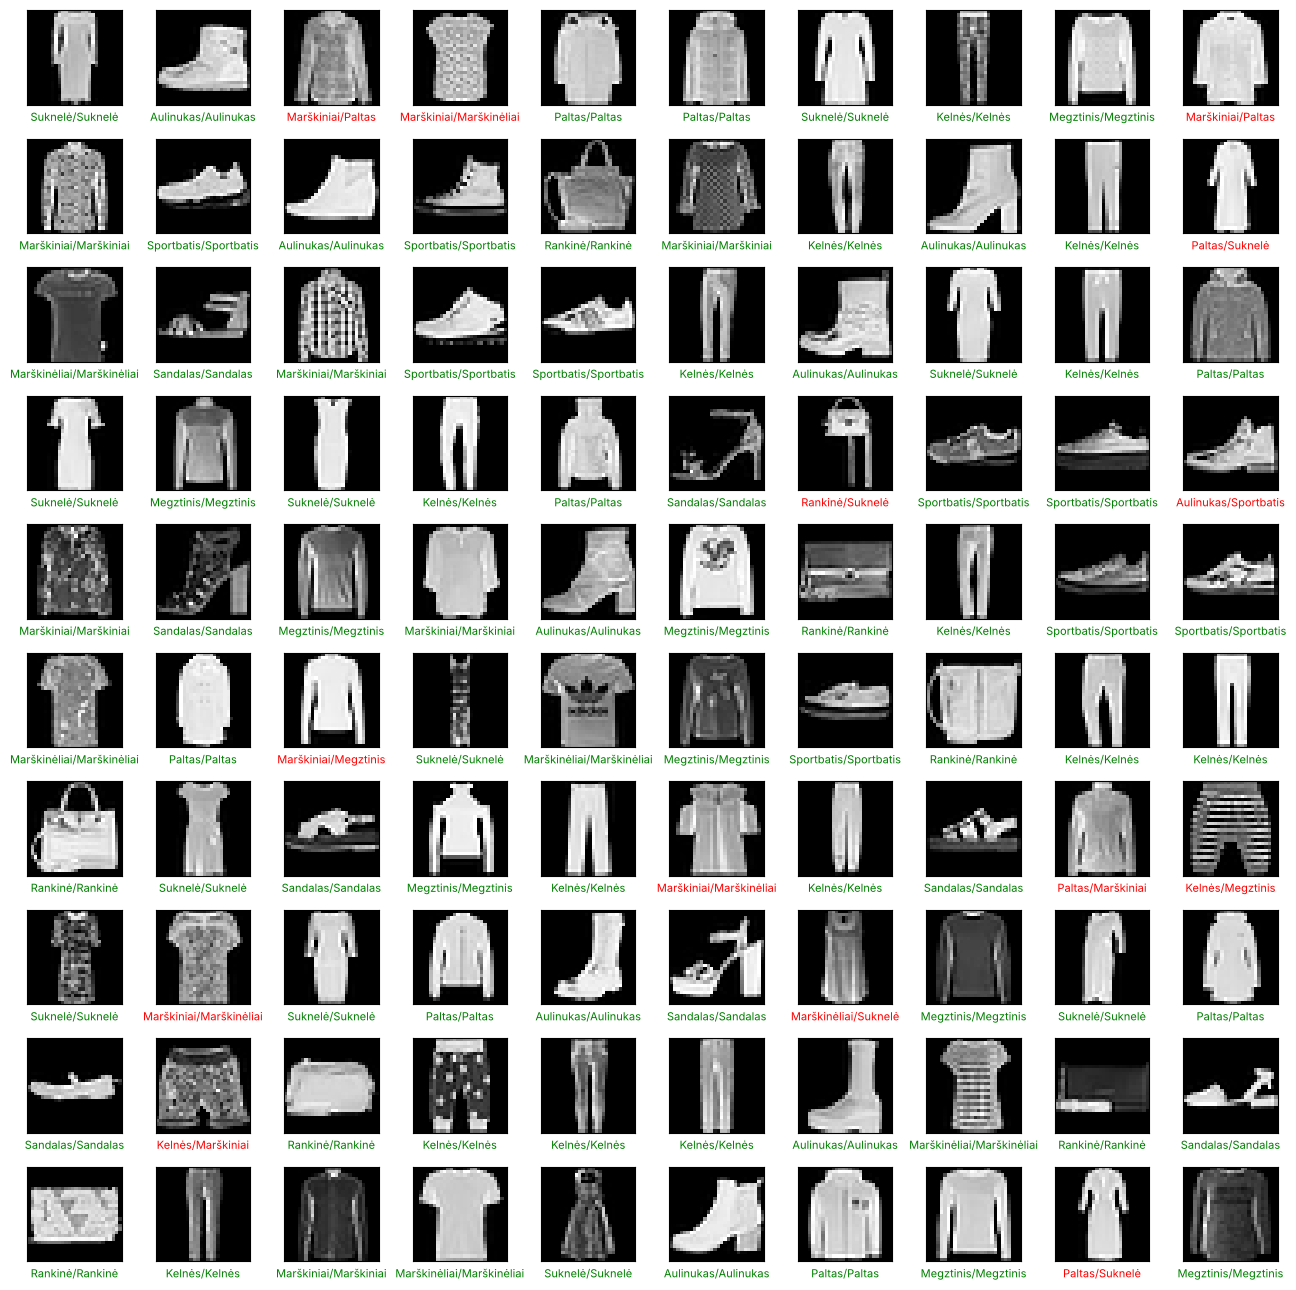

In [8]:
def plot_predictions(model, images, labels):
    predicted = np.argmax(model.predict(images[:100], verbose=0), axis=1)
    plt.figure(figsize=(13, 13))
    for i in range(100):
        plt.subplot(10, 10, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)
        plt.imshow(images[i].astype('uint8'))
        true_name, pred_name = class_names[labels[i][0]], class_names[predicted[i]]
        plt.xlabel(true_name + '/' + pred_name, color='green' if true_name == pred_name else 'red', fontsize=8)
    plt.tight_layout()
    plt.show()


plot_predictions(model, test_images, test_labels)

---
# 2 skyrius. Duomenų papildymas ir viso tinklo derinimas (*fine-tuning*)

Įkeliame išsaugotą modelį (kaip originale) ir pažiūrime, kurie sluoksniai mokomi.
Modelis turi tik 3 sluoksnius, nes visas EfficientNetV2-B1 yra vienas sluoksnis su daugybe vidinių sluoksnių.

In [9]:
model = keras.models.load_model(export_path)

for layer in model.layers:
    print(f'Sluoksnis: {layer.name}, mokomas (trainable): {layer.trainable}')

feature_extractor = model.layers[1]
print('EfficientNetV2-B1 viduje yra', len(feature_extractor.layers), 'sluoksniai(-ių)')

Sluoksnis: resizing, mokomas (trainable): True
Sluoksnis: efficientnetv2-b1, mokomas (trainable): False
Sluoksnis: dense, mokomas (trainable): True
EfficientNetV2-B1 viduje yra 335 sluoksniai(-ių)


### „Atšildome“ tinklą

* `feature_extractor.trainable = True`: dabar bus keičiami **visi** EfficientNet svoriai;
* **išskyrus** `BatchNormalization` sluoksnius. Jie saugo ImageNet nuotraukų statistiką (vidurkius ir dispersijas).
  Jei juos mokytume su mažais paketais iš mūsų visai kitokių nuotraukų, ta statistika „sugriūtų“ ir tinklas pamirštų, ką mokėjo.
  Tai rekomenduoja ir Keras dokumentacija;
* mokymosi greitį sumažiname 10 kartų (0,001 → 0,0001), kaip originale, kad dideli žingsniai nesugadintų jau išmoktų svorių;
* pakeitus `trainable`, modelį reikia **iš naujo sukompiliuoti** (originale to nebuvo).

In [10]:
feature_extractor.trainable = True
for layer in feature_extractor.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=keras.optimizers.Adam(learning_rate=1e-4),
              loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=['accuracy'])

print('Mokomų svorių masyvų:', len(model.trainable_weights), ' nemokomų:', len(model.non_trainable_weights))
print('Mokomų parametrų: {:,}'.format(sum(int(np.prod(w.shape)) for w in model.trainable_weights)))

Mokomų svorių masyvų: 151  nemokomų: 292
Mokomų parametrų: 6,801,790


### Duomenų papildymas (*data augmentation*)

Kad tinklas nepersimokytų, kiekvieną kartą jam rodome šiek tiek pakeistą nuotrauką: atspindėtą horizontaliai,
pasuktą iki ±10 % (36°), paslinktą iki 10 % ir šiek tiek pašviesintą arba patamsintą. Prekė lieka ta pati,
todėl tinklas mokosi atpažinti prekę, o ne įsiminti konkrečius taškus. Pasukus ar paslinkus nuotrauką, tušti kampai
užpildomi veidrodiniu atspindžiu, todėl kraštuose matyti „atspindėtos“ prekės dalys.

In [11]:
data_augmentation = keras.Sequential([
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.1),
    layers.RandomBrightness(factor=0.1, value_range=(0, 255)),
    layers.RandomTranslation(0.1, 0.1),
])

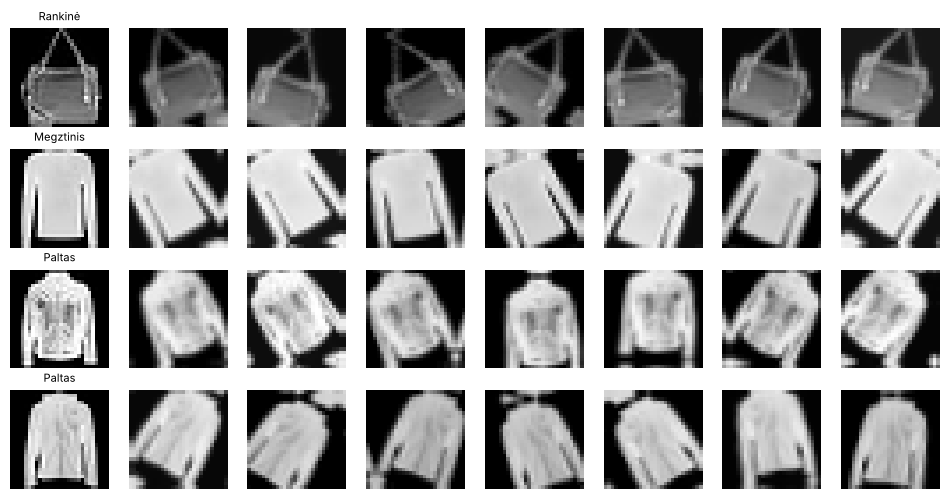

In [12]:
#@title Kaip atrodo papildytos nuotraukos: pirmame stulpelyje originalas, toliau 7 atsitiktiniai variantai

plt.figure(figsize=(12, 6))
for row in range(4):
    img = train_images[row]
    plt.subplot(4, 8, row * 8 + 1)
    plt.imshow(img.astype('uint8')); plt.axis('off'); plt.title(class_names[train_labels[row][0]], fontsize=8)
    for col in range(1, 8):
        aug = data_augmentation(img[None], training=True)[0].numpy()
        plt.subplot(4, 8, row * 8 + col + 1)
        plt.imshow(np.clip(aug, 0, 255).astype('uint8')); plt.axis('off')
plt.show()

Originale papildymas buvo pritaikomas visam masyvui iš karto, o ciklas `for i in range(100)` kas 2 epochas
iš naujo įkeldavo duomenis (iš viso 200 epochų, ~7 valandos su GPU). Čia naudojame `tf.data`:
papildymas atliekamas kiekvienam paketui iš naujo, todėl **kiekvienoje epochoje nuotraukos kitokios**.
Validavimui naudojame tas pačias paskutines 10 % mokymo nuotraukų kaip 1 skyriuje (be papildymo).

In [13]:
n_val = int(0.1 * len(train_images))
x_train, y_train = train_images[:-n_val], train_labels[:-n_val]
x_val, y_val = train_images[-n_val:], train_labels[-n_val:]

train_ds = (tf.data.Dataset.from_tensor_slices((x_train, y_train))
            .shuffle(len(x_train), seed=42)
            .batch(32)
            .map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
            .prefetch(tf.data.AUTOTUNE))

history_ft = model.fit(train_ds, validation_data=(x_val, y_val), epochs=3)

Epoch 1/3


.../site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


  1/169 ━━━━━━━━━━━━━━━━━━━━ 1:34:48 34s/step - accuracy: 0.5938 - loss: 1.0422

  2/169 ━━━━━━━━━━━━━━━━━━━━ 5:35 2s/step - accuracy: 0.6719 - loss: 0.8929    

  3/169 ━━━━━━━━━━━━━━━━━━━━ 5:45 2s/step - accuracy: 0.7188 - loss: 0.8169

...

166/169 ━━━━━━━━━━━━━━━━━━━━ 5s 2s/step - accuracy: 0.8848 - loss: 0.3189

167/169 ━━━━━━━━━━━━━━━━━━━━ 3s 2s/step - accuracy: 0.8851 - loss: 0.3179

168/169 ━━━━━━━━━━━━━━━━━━━━ 1s 2s/step - accuracy: 0.8852 - loss: 0.3172

169/169 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - accuracy: 0.8856 - loss: 0.3165

169/169 ━━━━━━━━━━━━━━━━━━━━ 295s 2s/step - accuracy: 0.8856 - loss: 0.3165 - val_accuracy: 0.8850 - val_loss: 0.3171


In [14]:
test_loss, test_acc = model.evaluate(test_images, test_labels)
finetuned_test_acc = test_acc
print('Užšaldytas tinklas: {:.4f}   Suderintas tinklas: {:.4f}'.format(frozen_test_acc, finetuned_test_acc))

 1/32 ━━━━━━━━━━━━━━━━━━━━ 17s 569ms/step - accuracy: 0.8438 - loss: 0.3814

 2/32 ━━━━━━━━━━━━━━━━━━━━ 15s 533ms/step - accuracy: 0.8750 - loss: 0.2940

 3/32 ━━━━━━━━━━━━━━━━━━━━ 15s 546ms/step - accuracy: 0.8958 - loss: 0.2635

 4/32 ━━━━━━━━━━━━━━━━━━━━ 15s 547ms/step - accuracy: 0.8984 - loss: 0.3170

 5/32 ━━━━━━━━━━━━━━━━━━━━ 14s 544ms/step - accuracy: 0.9125 - loss: 0.2835

...

30/32 ━━━━━━━━━━━━━━━━━━━━ 1s 560ms/step - accuracy: 0.8896 - loss: 0.3004

31/32 ━━━━━━━━━━━━━━━━━━━━ 0s 563ms/step - accuracy: 0.8901 - loss: 0.3017

32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 553ms/step - accuracy: 0.8910 - loss: 0.3003

32/32 ━━━━━━━━━━━━━━━━━━━━ 18s 554ms/step - accuracy: 0.8910 - loss: 0.3003


Užšaldytas tinklas: 0.8770   Suderintas tinklas: 0.8910


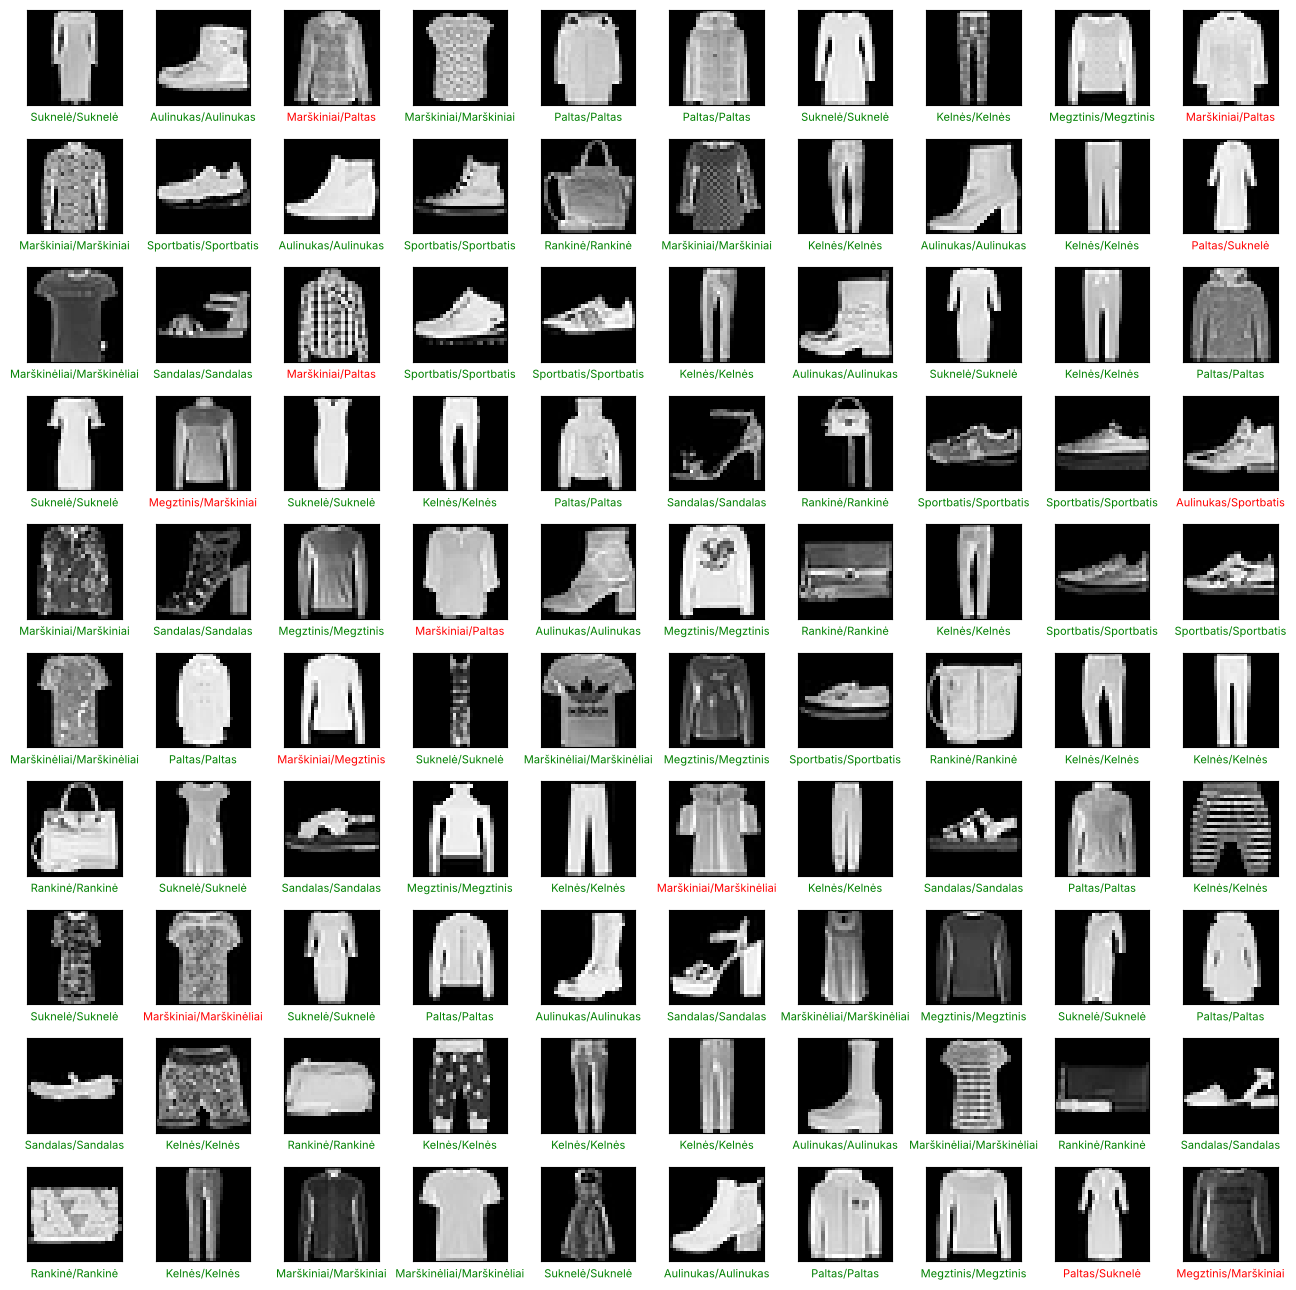

In [15]:
plot_predictions(model, test_images, test_labels)

---
# Išvados

| Modelis | Tikslumas (1 000 testavimo nuotraukų) | Mokomų parametrų |
|---|---|---|
| CNN nuo nulio (1.4 sąsiuvinis) | 85,2 % | 93 322 |
| EfficientNetV2-B1 užšaldytas + naujas `Dense` sluoksnis | 87,7 % | 12 810 |
| + viso tinklo derinimas su papildytais duomenimis (3 epochos) | **89,1 %** | 6 801 790 |

1. **Perkeliamasis mokymasis lenkia mokymą nuo nulio** net su užšaldytu tinklu, nors mokoma 7 kartus mažiau parametrų
   nei 1.4 sąsiuvinio CNN. Visą „sunkų darbą“ (požymių išskyrimą) jau atliko ImageNet išmokytas tinklas.
2. **Derinimas pridėjo dar 1,4 procentinio punkto.** Pirmoje derinimo epochoje validavimo tikslumas *nukrito* nuo 87 % iki 80 %:
   atšildžius visus svorius, pirmieji žingsniai išderina išmoktus požymius, be to, papildytos nuotraukos yra sunkesnės.
   Originale buvo tas pats (89 % → ~87 %). Po 3 epochų tinklas prisitaikė ir pralenkė užšaldytą variantą (88,5 % validavimo aibėje).
3. **Pagerėjimas mažesnis nei originale** (CIFAR-10: nuo 70 % iki 89 %), nes Fashion-MNIST nuotraukos yra mažos (28×28),
   nespalvotos ir labai skiriasi nuo ImageNet nuotraukų: padidintos iki 240×240 jos tampa neryškios.
4. **Klaidos tos pačios kaip 1.4 sąsiuvinyje:** marškiniai, paltai, megztiniai ir marškinėliai painiojami tarpusavyje.
5. **Kaina:** EfficientNetV2-B1 turi 6,9 mln. parametrų (modelio failas 29 MB, 1.4 sąsiuvinio CNN ~0,4 MB), o mokymas
   be GPU užtruko apie pusvalandį. Su 1 000 testavimo nuotraukų 1–2 procentinių punktų skirtumas yra 10–20 nuotraukų,
   todėl kitu atsitiktiniu paleidimu skaičiai gali šiek tiek skirtis.